## Site Covariance
Explore model error covariance between sites

In [1]:
# Run settings
site_1 = 'Elk Cabin'
site_2 = 'Wesner Springs'
namelist = 'ghec'
forcing_str = '01011010'
version = '0004'
isAlpine = True

In [2]:
# Load environmental variables if on Alpine, otherwise they should be stored
import os

# Configure environmental variables
if isAlpine:
    os.environ['OUTPUT_PATH'] = r'/projects/ccox1@xsede.org/lm4px_modelling/output' #Alpine
    os.environ['SNOTEL_PATH'] = r'/projects/ccox1@xsede.org/data/snotel/'
    os.environ['FORCING_PATH'] = r'/projects/ccox1@xsede.org/lm4px_modelling/forcing/'

In [3]:
%matplotlib ipympl
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd
#from model_datasets.forcing import LM4Forcing
from model_datasets.output import LM4ModelOutput 
from buildforcing.datasets import PNNLSnotel

Load datasets

In [4]:
model_1 = LM4ModelOutput(site=site_1, forcing_string=forcing_str, namelist=namelist, version=version, spinup=False)
model_2 = LM4ModelOutput(site=site_2, forcing_string=forcing_str, namelist=namelist, version=version, spinup=False)

In [5]:
daily_vars = model_1.get_variables(diag='land_daily')
monthly_vars = model_1.get_variables(diag='land_month')

In [6]:
snotel_1 = PNNLSnotel(site_1, os.environ['SNOTEL_PATH'])
snotel_2 = PNNLSnotel(site_2, os.environ['SNOTEL_PATH'])
snotel_1.load_data()
snotel_2.load_data()

### Calculate daily error

In [7]:
snotel_2.data.head()

,T_max_C,T_min_C,T_avg_C,precip_mm,swe_mm
Date,,,,,
1989-09-26 00:00:00-06:00,13.405556,13.405556,13.405556,NaN,NaN
1989-09-27 00:00:00-06:00,16.266667,3.677778,7.683333,NaN,NaN
1989-09-28 00:00:00-06:00,17.983333,3.677778,8.827778,NaN,NaN
1989-09-29 00:00:00-06:00,16.838889,2.533333,8.255556,NaN,NaN
1989-09-30 00:00:00-06:00,16.266667,4.250000,8.827778,NaN,NaN


In [8]:
model_snow_1 = model_1.get_data(['snow'],'land_daily')
model_snow_2 = model_2.get_data(['snow'],'land_daily')

# Combine model datasets into one dataframe
combined_data = pd.merge(model_snow_1['snow'], model_snow_2['snow'], how='outer', left_index=True, right_index=True, suffixes=('_1', '_2'))


Since all timezones in the western US don't exceed UTC-9, we can safely remove timezones for merging purposes.

In [9]:
# Combine with snotel data
snotel_swe_1 = snotel_1.data['swe_mm']
snotel_swe_2 = snotel_2.data['swe_mm']

# Remove timezone from index
snotel_swe_1.index = snotel_swe_1.index.tz_localize(None)
snotel_swe_2.index = snotel_swe_2.index.tz_localize(None)

# Shift snotel data by 12 hours to match model output time
snotel_swe_1.index = snotel_swe_1.index + pd.Timedelta(hours=12)
snotel_swe_2.index = snotel_swe_2.index + pd.Timedelta(hours=12)

combined_data = pd.merge(combined_data, snotel_swe_1, how='left', left_index=True, right_index=True)
combined_data = pd.merge(combined_data, snotel_swe_2, how='left', left_index=True, right_index=True, suffixes=('_1', '_2'))

In [10]:
# Calculate the daily error between model and snotel
combined_data['error_1'] = combined_data['snow_1'] - combined_data['swe_mm_1']
combined_data['error_2'] = combined_data['snow_2'] - combined_data['swe_mm_2']

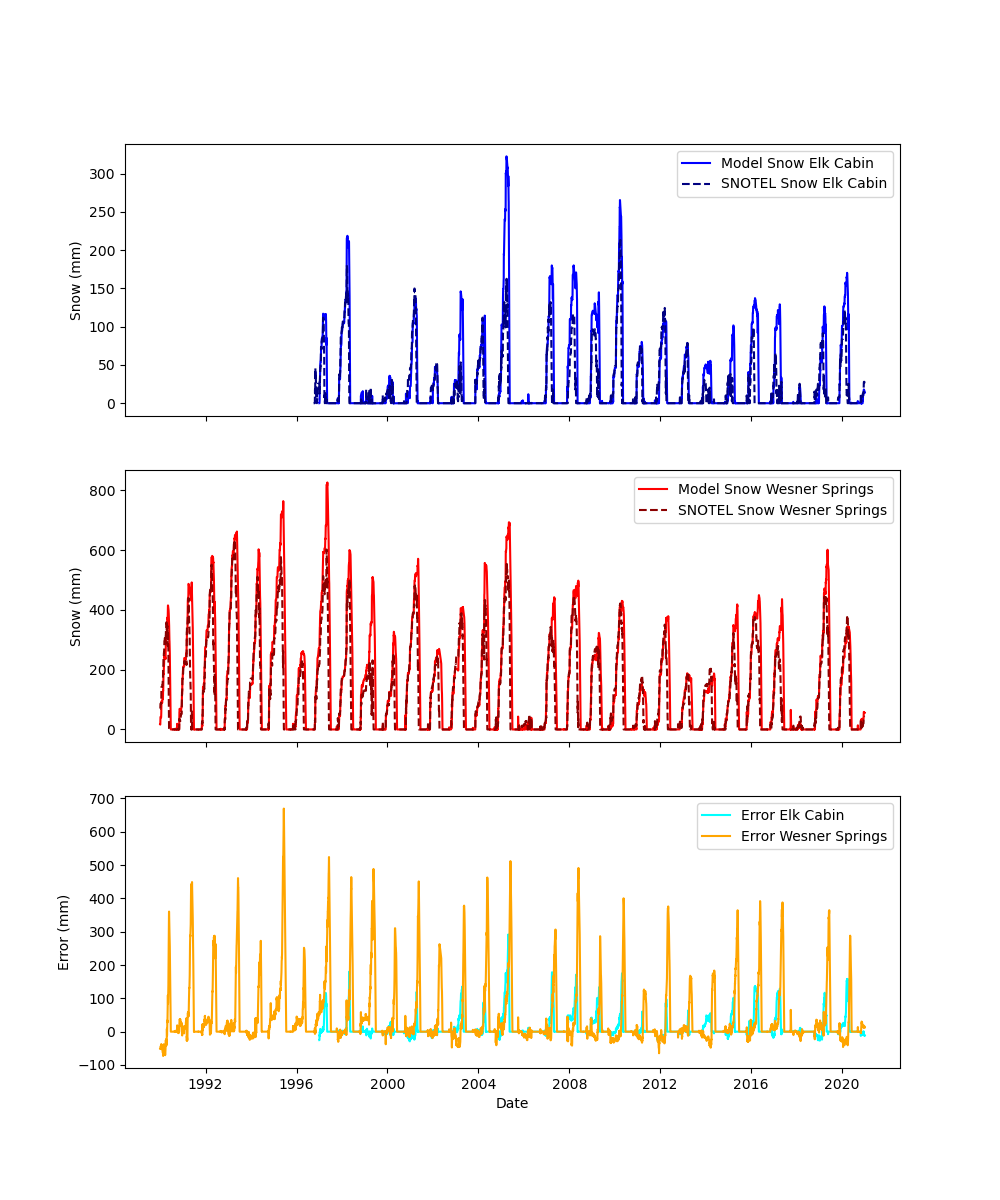

In [11]:
# Plot snow and error in one figure with three subplots
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 12), sharex=True)
# First subplot: Model Snow vs SNOTEL Snow for site_1
ax1.plot(combined_data.index, combined_data['snow_1'], label=f'Model Snow {site_1}', color='blue')
ax1.plot(combined_data.index, combined_data['swe_mm_1'], label=f'SNOTEL Snow {site_1}', color='navy', linestyle='--')
ax1.set_ylabel('Snow (mm)')
ax1.legend()

# Second subplot: Model Snow vs SNOTEL Snow for site_2
ax2.plot(combined_data.index, combined_data['snow_2'], label=f'Model Snow {site_2}', color='red')
ax2.plot(combined_data.index, combined_data['swe_mm_2'], label=f'SNOTEL Snow {site_2}', color='darkred', linestyle='--')
ax2.set_ylabel('Snow (mm)')
ax2.legend()

# Third subplot: Error for both sites
ax3.plot(combined_data.index, combined_data['error_1'], label=f'Error {site_1}', color='cyan')
ax3.plot(combined_data.index, combined_data['error_2'], label=f'Error {site_2}', color='orange')
ax3.set_ylabel('Error (mm)')
ax3.set_xlabel('Date')
ax3.legend()

- Melt season is going to be especially tricky because 

### Scatter plots

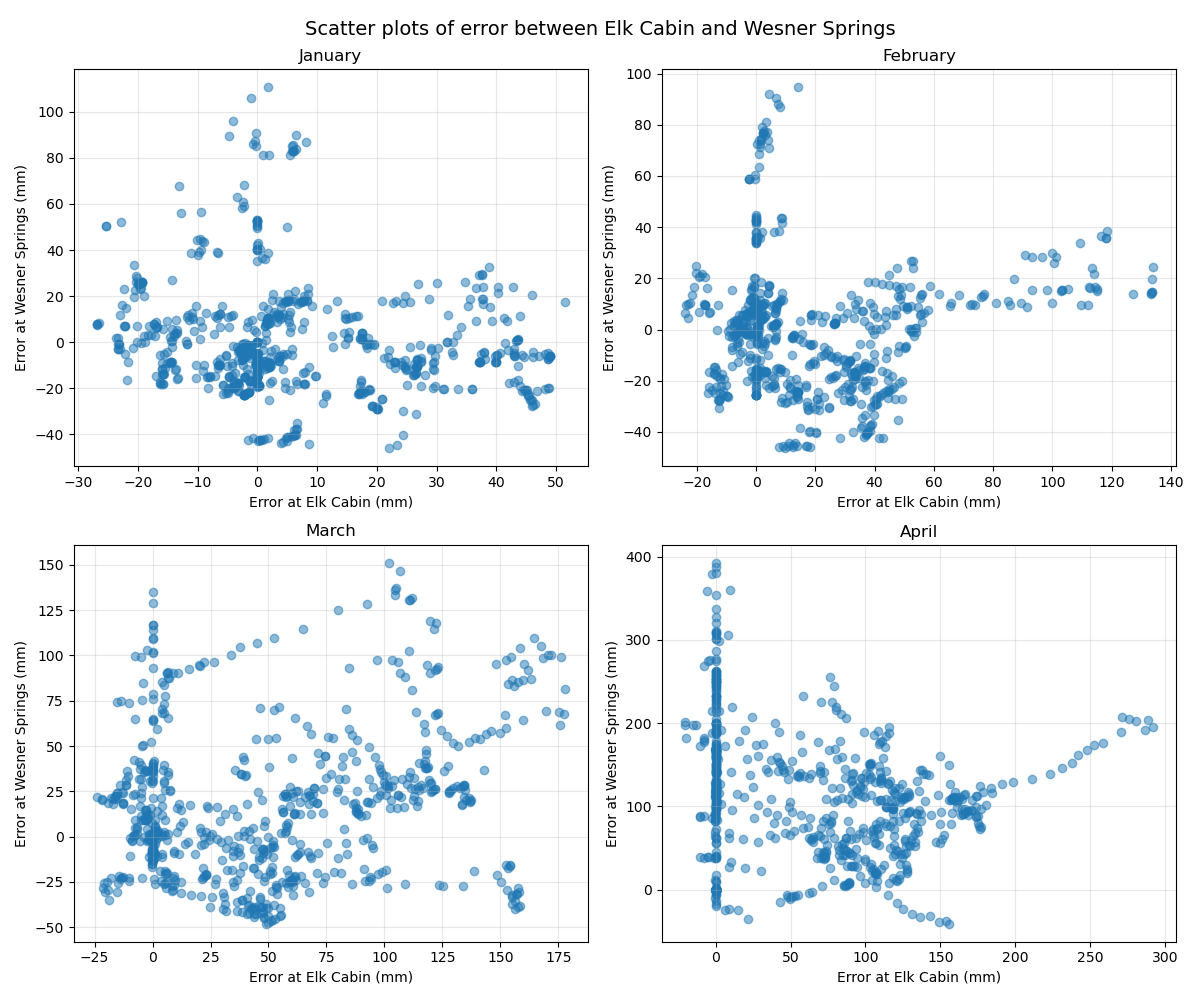

In [12]:
# Scatter plots for jan, feb, mar, apr (excluding first year)
# Filter out the first year of data for plotting
combined_data_filtered = combined_data[combined_data.index.year > combined_data.index.year.min()]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

months = [1, 2, 3, 4]
month_names = ['January', 'February', 'March', 'April']

for i, (month, month_name) in enumerate(zip(months, month_names)):
    row = i // 2
    col = i % 2
    month_values = combined_data_filtered[combined_data_filtered.index.month == month]
    axes[row, col].scatter(month_values['error_1'], month_values['error_2'], alpha=0.5)
    axes[row, col].set_xlabel('Error at ' + site_1 + ' (mm)')
    axes[row, col].set_ylabel('Error at ' + site_2 + ' (mm)')
    axes[row, col].set_title(month_name)
    axes[row, col].grid(True, alpha=0.3)

plt.suptitle('Scatter plots of error between ' + site_1 + ' and ' + site_2, fontsize=14)
plt.tight_layout()